In [22]:
# ============================== CONFIG — edit this cell only ==============================
# Point DATA at the folder that contains the gdb_export CSVs (trees.csv, soil_samples.csv, soil_fractions.csv).
# ArcGIS Pro example:  DATA = r'C:\Users\you\Documents\Fernow\gdb_export'
import os
DATA = r'C:\Users\DCifelli2\OneDrive - mercercounty.org\Documents\ArcGIS\Projects\Fernow-FM-SOM-DC-092026\gdb_export'          # <-- EDIT ME if the notebook is not sitting next to the gdb_export folder

# If True, the ecosystem-C figure scales POM/MAOM so their sum equals bulk soil C (mass-balance-consistent stack).
# If False, POM/MAOM are plotted exactly as measured (fraction recovery 86-113% of bulk; both are defensible,
# the choice just has to be stated in the caption).
SCALE_FRACTIONS_TO_BULK = True
# ==========================================================================================

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 40)

ORDER  = ['WS4', 'WS2', 'WS5']                       # REF, DLC, STS — keep this order everywhere
LABELS = {'WS4': 'REF', 'WS2': 'DLC', 'WS5': 'STS'}
COLORS = {'WS4': '#4C6444', 'WS2': '#B0733A', 'WS5': '#3A6EA5'}

for f in ['trees.csv', 'soil_samples.csv', 'soil_fractions.csv']:
    assert os.path.exists(os.path.join(DATA, f)), f'Cannot find {f} in DATA — fix the DATA path above.'
print('scipy', __import__('scipy').__version__, '| pandas', pd.__version__, '| data folder OK')


scipy 1.9.3 | pandas 2.0.2 | data folder OK


In [23]:
# ---------- Shared statistical helpers (no packages beyond scipy needed) ----------

def welch_anova(groups):
    """Welch's heteroscedasticity-robust one-way ANOVA (matches R oneway.test var.equal=FALSE)."""
    k = len(groups); n = np.array([len(g) for g in groups], float)
    m = np.array([g.mean() for g in groups]); v = np.array([g.var(ddof=1) for g in groups])
    w = n / v
    grand = np.sum(w * m) / np.sum(w)
    num = np.sum(w * (m - grand) ** 2) / (k - 1)
    tmp = np.sum((1 - w / np.sum(w)) ** 2 / (n - 1))
    F = num / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df2 = (k ** 2 - 1) / (3 * tmp)
    return F, 1 - stats.f.cdf(F, k - 1, df2)

def dunnett_vs_control(groups):
    """Dunnett's test vs. groups[0]. Uses scipy.stats.dunnett when available (SciPy >= 1.11);
    otherwise falls back to Welch t-tests vs. control with Holm correction (slightly conservative)
    and says so, so the output is never silently different between environments."""
    try:
        from scipy.stats import dunnett as _dunnett
        res = _dunnett(*groups[1:], control=groups[0])
        return list(res.pvalue), 'Dunnett (scipy)'
    except ImportError:
        p = [stats.ttest_ind(g, groups[0], equal_var=False).pvalue for g in groups[1:]]
        order = np.argsort(p); m = len(p); adj = np.empty(m)
        running = 0.0
        for rank, idx in enumerate(order):
            running = max(running, (m - rank) * p[idx]); adj[idx] = min(running, 1.0)
        return list(adj), 'Welch t + Holm (scipy<1.11 fallback)'

def bh_fdr(pvals):
    """Benjamini-Hochberg adjusted p-values (manual — statsmodels not in arcgispro-py3)."""
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); ranked = p[order] * m / (np.arange(m) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(m); out[order] = np.minimum(ranked, 1.0)
    return out

def anova_power(groups, alpha=0.05):
    """Post-hoc power for the one-way ANOVA via the noncentral F distribution."""
    m = [g.mean() for g in groups]
    pooled = np.mean([g.var(ddof=1) for g in groups])
    f_eff = np.sqrt(np.mean([(x - np.mean(m)) ** 2 for x in m]) / pooled)   # Cohen's f
    N = sum(len(g) for g in groups); k = len(groups)
    nc = f_eff ** 2 * N
    fcrit = stats.f.ppf(1 - alpha, k - 1, N - k)
    return f_eff, stats.ncf.sf(fcrit, k - 1, N - k, nc)

def battery(groups):
    """Full assumption-checked battery. groups[0] must be REF."""
    groups = [np.asarray(g, float) for g in groups]
    groups = [g[~np.isnan(g)] for g in groups]
    F, p = stats.f_oneway(*groups)
    _, lev_p = stats.levene(*groups)
    _, sh_p = stats.shapiro(np.concatenate([g - g.mean() for g in groups]))
    H, pk = stats.kruskal(*groups)
    Fw, pw = welch_anova(groups)
    dun_p, dun_method = dunnett_vs_control(groups)
    f_eff, power = anova_power(groups)
    return dict(n=[len(g) for g in groups], means=[g.mean() for g in groups],
                sds=[g.std(ddof=1) for g in groups], F=F, p=p, lev_p=lev_p, sh_p=sh_p,
                Fw=Fw, pw=pw, H=H, pk=pk, dunnett_p=dun_p, dunnett_method=dun_method,
                f_eff=f_eff, power=power)

print('Helpers loaded.')

Helpers loaded.


In [24]:
trees = pd.read_csv(os.path.join(DATA, 'trees.csv'))
trees = trees[trees.dbh_cm.notna()].copy()
PLOT_AREA_M2 = 404.70782
trees['agbC_kg'] = trees['agb_kg_jenkins'] * 0.48

agb_plot = trees.groupby(['watershed', 'plot_id'])['agbC_kg'].sum().reset_index()
agb_plot['MgC_ha'] = agb_plot['agbC_kg'] / 1000 / (PLOT_AREA_M2 / 10000)

summary = agb_plot.groupby('watershed')['MgC_ha'].agg(['count', 'mean', 'std']).reindex(ORDER)
summary.index = [LABELS[w] for w in summary.index]
print('AGB-C by watershed (Mg C/ha), plot level:'); print(summary.round(1))

groups = [agb_plot[agb_plot.watershed == w]['MgC_ha'].values for w in ORDER]
r = battery(groups)
print(f"\nANOVA F={r['F']:.2f} p={r['p']:.4f} | Levene p={r['lev_p']:.4f} (fails -> lead with Welch/KW) | Shapiro p={r['sh_p']:.4f}")
print(f"Welch p={r['pw']:.4f} | Kruskal-Wallis p={r['pk']:.4f}")
print(f"{r['dunnett_method']} vs REF: DLC p={r['dunnett_p'][0]:.4f}, STS p={r['dunnett_p'][1]:.4f}")
print(f"Cohen's f={r['f_eff']:.2f}, power={r['power']:.2f}")


AGB-C by watershed (Mg C/ha), plot level:
     count   mean   std
REF      6  177.4  44.8
DLC      6   89.0  14.8
STS      6   90.6  42.4

ANOVA F=11.46 p=0.0010 | Levene p=0.0385 (fails -> lead with Welch/KW) | Shapiro p=0.8647
Welch p=0.0072 | Kruskal-Wallis p=0.0083
Welch t + Holm (scipy<1.11 fallback) vs REF: DLC p=0.0072, STS p=0.0072
Cohen's f=1.13, power=0.98


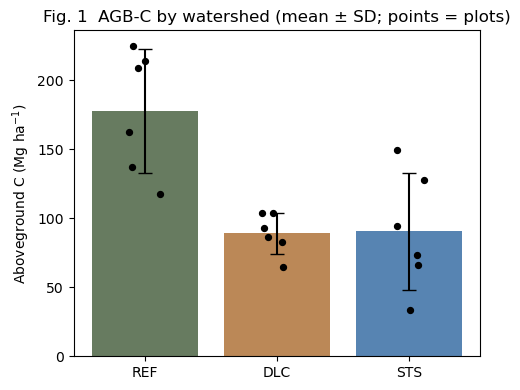

In [25]:
fig, ax = plt.subplots(figsize=(5, 4))
for i, w in enumerate(ORDER):
    vals = agb_plot[agb_plot.watershed == w]['MgC_ha'].values
    ax.bar(i, vals.mean(), yerr=vals.std(ddof=1), capsize=5, color=COLORS[w], alpha=0.85)
    ax.scatter(np.full(len(vals), i) + np.random.uniform(-0.12, 0.12, len(vals)), vals,
               color='k', zorder=3, s=18)
ax.set_xticks(range(3)); ax.set_xticklabels([LABELS[w] for w in ORDER])
ax.set_ylabel('Aboveground C (Mg ha$^{-1}$)')
ax.set_title('Fig. 1  AGB-C by watershed (mean ± SD; points = plots)')
plt.tight_layout(); plt.show()

In [26]:
full_plots = agb_plot[['watershed', 'plot_id']].drop_duplicates()
mid = trees[trees.dbh_cm >= 27.9].groupby(['watershed', 'plot_id']).size().reset_index(name='n')
mid = full_plots.merge(mid, how='left').fillna(0)
g = [mid[mid.watershed == w]['n'].values for w in ORDER]
print(f'Stems >=27.9 cm per plot: ANOVA p={stats.f_oneway(*g)[1]:.3f}  (expected n.s.)')

big = trees[trees.dbh_cm >= 50]
print('\nStems >=50 cm by watershed:'); print(big.groupby('watershed').size().reindex(ORDER).fillna(0).astype(int))
ref_t = trees[trees.watershed == 'WS4']
share = ref_t.loc[ref_t.dbh_cm >= 50, 'agbC_kg'].sum() / ref_t['agbC_kg'].sum() * 100
print(f'\nShare of pooled REF AGB-C in >=50 cm stems: {share:.0f}%')
print('Largest stem (cm):', trees.groupby('watershed')['dbh_cm'].max().reindex(ORDER).round(1).to_dict())


Stems >=27.9 cm per plot: ANOVA p=0.347  (expected n.s.)

Stems >=50 cm by watershed:
watershed
WS4    17
WS2     0
WS5    10
dtype: int32

Share of pooled REF AGB-C in >=50 cm stems: 70%
Largest stem (cm): {'WS4': 92.5, 'WS2': 47.0, 'WS5': 71.4}


In [27]:
soil = pd.read_csv(os.path.join(DATA, 'soil_samples.csv'))
resp = ['soil_C_gm2', 'soil_N_gm2', 'soil_CN', 'fine_root_gm2', 'BD_gcm3']
soil_plot = soil.groupby(['watershed', 'soil_plot', 'depth_code'])[resp].mean().reset_index()

rows = []
for var in resp:
    for depth in ['OH', '0-20', '20-40']:
        if var == 'BD_gcm3' and depth == 'OH':
            continue
        d = soil_plot[soil_plot.depth_code == depth]
        g = [d[d.watershed == w][var].dropna().values for w in ORDER]
        r = battery(g)
        rows.append(dict(variable=var, depth=depth,
                         REF=round(r['means'][0], 2), DLC=round(r['means'][1], 2), STS=round(r['means'][2], 2),
                         ANOVA_p=round(r['p'], 4), Welch_p=round(r['pw'], 4), KW_p=round(r['pk'], 4),
                         Levene_p=round(r['lev_p'], 4), Shapiro_p=round(r['sh_p'], 4),
                         Dunnett_DLC=round(r['dunnett_p'][0], 4), Dunnett_STS=round(r['dunnett_p'][1], 4),
                         f=round(r['f_eff'], 2), power=round(r['power'], 2)))
soil_results = pd.DataFrame(rows)

# FDR across the exploratory battery (manual Benjamini-Hochberg)
soil_results['ANOVA_p_FDR'] = bh_fdr(soil_results['ANOVA_p']).round(4)
soil_results['KW_p_FDR'] = bh_fdr(soil_results['KW_p']).round(4)
soil_results

,variable,depth,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,Levene_p,Shapiro_p,Dunnett_DLC,Dunnett_STS,f,power,ANOVA_p_FDR,KW_p_FDR
0,soil_C_gm2,OH,81.56,32.68,49.34,0.0898,0.1032,0.0214,0.3010,0.0019,0.1080,0.2328,0.56,0.47,0.2710,0.1554
1,soil_C_gm2,0-20,5861.81,5325.73,4195.17,0.2086,0.0436,0.0691,0.3391,0.1103,0.6358,0.0310,0.44,0.31,0.2920,0.1935
2,soil_C_gm2,20-40,2511.83,2711.57,1879.55,0.1776,0.1359,0.2291,0.4996,0.0768,0.7013,0.2580,0.46,0.34,0.2920,0.3564
3,soil_N_gm2,OH,2.79,1.25,1.76,0.0518,0.0432,0.0222,0.3801,0.0024,0.0425,0.1767,0.64,0.58,0.2710,0.1554
4,soil_N_gm2,0-20,371.53,293.34,260.22,0.1407,0.1180,0.1345,0.3905,0.5892,0.2484,0.0930,0.50,0.38,0.2870,0.2616
5,soil_N_gm2,20-40,186.55,187.51,172.33,0.8096,0.7510,0.9107,0.4970,0.0304,1.0000,1.0000,0.15,0.08,0.8719,0.9808
6,soil_CN,OH,28.99,25.48,28.58,0.4448,0.4041,0.4758,0.5216,0.5444,0.5414,0.9003,0.31,0.17,0.5661,0.5551
7,soil_CN,0-20,16.04,17.49,16.43,0.6430,0.5553,0.4758,0.5161,0.1957,0.6024,0.8328,0.22,0.11,0.7502,0.5551
8,soil_CN,20-40,12.99,13.98,10.72,0.0600,0.1695,0.0947,0.2037,0.9996,0.4020,0.2008,0.62,0.55,0.2710,0.2210
9,fine_root_gm2,OH,4.66,8.97,4.20,0.1435,0.0736,0.0691,0.7191,0.0062,0.3361,0.8738,0.50,0.38,0.2870,0.1935


In [28]:
# Total mineral-soil C stock, 0-40 cm (Mg/ha) — the belowground headline stock number
wide = soil_plot.pivot_table(index=['watershed', 'soil_plot'], columns='depth_code',
                             values='soil_C_gm2').reset_index()
wide['SoilC_0_40'] = (wide['0-20'] + wide['20-40']) / 100
g = [wide[wide.watershed == w]['SoilC_0_40'].values for w in ORDER]
r = battery(g)
print('Soil C 0-40 cm (Mg/ha):', {LABELS[w]: round(m, 1) for w, m in zip(ORDER, r['means'])})
print(f"ANOVA p={r['p']:.3f} | Welch p={r['pw']:.3f} | KW p={r['pk']:.3f} | power={r['power']:.2f} -> 'not detected'")


Soil C 0-40 cm (Mg/ha): {'REF': 83.7, 'DLC': 80.4, 'STS': 60.7}
ANOVA p=0.105 | Welch p=0.060 | KW p=0.114 | power=0.44 -> 'not detected'


In [29]:
frac = pd.read_csv(os.path.join(DATA, 'soil_fractions.csv'))
sub40 = frac[frac.depth_code == '20-40'].copy()
print(sub40[['watershed', 'soil_plot', 'LF_g', 'LF_C_gm2']].sort_values(['watershed', 'soil_plot']).to_string(index=False))
print('\nLeft-censored LF %C non-detects:', int(sub40['LF_C_gm2'].isna().sum()), '(all WS5)')


watershed  soil_plot   LF_g    LF_C_gm2
      WS2          7 0.0930  954.911983
      WS2          8 0.1274 1628.520484
      WS2          9 0.1743 1306.047920
      WS2         10 0.0434  645.617923
      WS2         11 0.0641  917.210033
      WS2         12 0.0429  605.863059
      WS4         13 0.0367  436.726013
      WS4         14 0.0442  602.875285
      WS4         15 0.0370  308.729519
      WS4         16 0.0456  532.095083
      WS4         17 0.0422  409.419850
      WS4         18 0.0241  424.781207
      WS5         19 0.0190         NaN
      WS5         20 0.0236         NaN
      WS5         21 0.0335  506.643344
      WS5         22 0.0682  811.488940
      WS5         23 0.0253         NaN
      WS5         24 0.0388  706.756760

Left-censored LF %C non-detects: 3 (all WS5)


In [30]:
ref = sub40.loc[sub40.watershed == 'WS4', 'LF_C_gm2'].values
dlc = sub40.loc[sub40.watershed == 'WS2', 'LF_C_gm2'].values
sts = sub40.loc[sub40.watershed == 'WS5', 'LF_C_gm2'].values
dl_floor = frac['LF_C_gm2'].dropna().min()     # smallest observed value = detection-limit proxy

sts_cc = sts[~np.isnan(sts)]
F, p = stats.f_oneway(ref, dlc, sts_cc)
t, pt = stats.ttest_ind(dlc, ref, equal_var=False)
print('PRIMARY — subsoil (20-40 cm) light-fraction CARBON:')
print(f'  Means (gC/m2): REF={ref.mean():.0f}  DLC={dlc.mean():.0f}  STS(detected n=3)={sts_cc.mean():.0f}')
print(f'  DLC/REF enrichment: {dlc.mean()/ref.mean():.2f}x')
print(f'  Focal contrast DLC vs REF (Welch t): p={pt:.4f}')
print(f'  3-group ANOVA (complete-case): p={p:.4f}')

print('\nSENSITIVITY — 3 STS non-detects substituted (STS back to n=6):')
for label, val in [('zero', 0.0), ('half detection limit', dl_floor / 2), ('full detection limit', dl_floor)]:
    sts_f = np.where(np.isnan(sts), val, sts)
    print(f'  {label:22s} STS mean={sts_f.mean():7.1f}   ANOVA p={stats.f_oneway(ref, dlc, sts_f)[1]:.4f}')


PRIMARY — subsoil (20-40 cm) light-fraction CARBON:
  Means (gC/m2): REF=452  DLC=1010  STS(detected n=3)=675
  DLC/REF enrichment: 2.23x
  Focal contrast DLC vs REF (Welch t): p=0.0168
  3-group ANOVA (complete-case): p=0.0127

SENSITIVITY — 3 STS non-detects substituted (STS back to n=6):
  zero                   STS mean=  337.5   ANOVA p=0.0057
  half detection limit   STS mean=  414.7   ANOVA p=0.0048
  full detection limit   STS mean=  491.8   ANOVA p=0.0042


In [31]:
# Supplementary: dry-mass basis (complete data, no censoring) — same story, kept for SI
sub40['LF_massfrac'] = sub40['LF_g'] / sub40['frac_soil_wt_g']
gm = [sub40.loc[sub40.watershed == w, 'LF_massfrac'].values for w in ORDER]
print(f'SI check, LF dry-mass fraction 20-40cm: DLC/REF = {gm[1].mean()/gm[0].mean():.2f}x, '
      f'ANOVA p={stats.f_oneway(*gm)[1]:.4f}, KW p={stats.kruskal(*gm)[1]:.4f}')


SI check, LF dry-mass fraction 20-40cm: DLC/REF = 2.30x, ANOVA p=0.0169, KW p=0.0195


In [32]:
# Full fraction battery, both depths (POM = LF + hPOM computed with half-DL fill for the 3 censored LF values,
# flagged in output; MAOC:totalPOC carried through but pre-flagged as fragile from prior rounds)
frac['LF_C_filled'] = frac['LF_C_gm2'].fillna(dl_floor / 2)
frac['POM_C_gm2'] = frac['LF_C_filled'] + frac['hPOM_C_gm2']

out = []
for var in ['LF_C_gm2', 'hPOM_C_gm2', 'POM_C_gm2', 'MAOM_C_gm2', 'MAOC_tot_POC']:
    for depth in ['0-20', '20-40']:
        d = frac[frac.depth_code == depth]
        g = [d.loc[d.watershed == w, var].dropna().values for w in ORDER]
        r = battery(g)
        out.append(dict(variable=var, depth=depth,
                        REF=round(r['means'][0], 1), DLC=round(r['means'][1], 1), STS=round(r['means'][2], 1),
                        ANOVA_p=round(r['p'], 4), Welch_p=round(r['pw'], 4), KW_p=round(r['pk'], 4),
                        Levene_p=round(r['lev_p'], 4)))
frac_results = pd.DataFrame(out)
frac_results

,variable,depth,REF,DLC,STS,ANOVA_p,Welch_p,KW_p,Levene_p
0,LF_C_gm2,0-20,1604.6,1864.3,1335.2,0.7875,0.5796,0.2401,0.7438
1,LF_C_gm2,20-40,452.4,1009.7,675.0,0.0127,0.0401,0.0079,0.1197
2,hPOM_C_gm2,0-20,950.5,977.6,1158.5,0.9184,0.9146,0.6525,0.8258
3,hPOM_C_gm2,20-40,285.4,523.1,155.4,0.3950,0.1353,0.1345,0.4905
4,POM_C_gm2,0-20,2555.1,2841.9,2493.7,0.9282,0.8575,0.4928,0.5401
5,POM_C_gm2,20-40,737.8,1532.8,570.1,0.0372,0.1516,0.0260,0.2521
6,MAOM_C_gm2,0-20,2546.4,3156.9,2374.3,0.5501,0.5860,0.5475,0.6568
7,MAOM_C_gm2,20-40,1385.8,1582.0,1139.9,0.4034,0.2532,0.2086,0.6077
8,MAOC_tot_POC,0-20,1.4,1.1,1.1,0.6751,0.7816,0.9268,0.2145
9,MAOC_tot_POC,20-40,1.9,1.3,4.7,0.0440,0.1039,0.0644,0.0128


In [33]:
# Pool computation (watershed means)
agb_ws = agb_plot.groupby('watershed')['MgC_ha'].mean()

oh_ws = soil_plot[soil_plot.depth_code == 'OH'].groupby('watershed')['soil_C_gm2'].mean() / 100

root_ws = (soil_plot[soil_plot.depth_code.isin(['0-20', '20-40'])]
           .groupby(['watershed', 'soil_plot'])['fine_root_gm2'].sum()
           .groupby('watershed').mean()) / 100 * 0.48

bulk_ws = wide.groupby('watershed')['SoilC_0_40'].mean()

frac_plot = frac.groupby(['watershed', 'soil_plot'])[['POM_C_gm2', 'MAOM_C_gm2']].sum() / 100
frac_ws = frac_plot.groupby('watershed').mean()

recovery = (frac_ws.sum(axis=1) / bulk_ws)
print('Fraction-sum / bulk-C recovery by watershed:', recovery.round(2).to_dict())

if SCALE_FRACTIONS_TO_BULK:
    pom_ws  = frac_ws['POM_C_gm2']  / recovery
    maom_ws = frac_ws['MAOM_C_gm2'] / recovery
    basis_note = 'POM/MAOM scaled to bulk soil C (mass-balance-consistent)'
else:
    pom_ws, maom_ws = frac_ws['POM_C_gm2'], frac_ws['MAOM_C_gm2']
    basis_note = 'POM/MAOM as measured (recovery 86-113% of bulk)'

eco = pd.DataFrame({'Aboveground': agb_ws, 'Fine roots': root_ws, 'Forest floor (OH)': oh_ws,
                    'POM-C (LF+hPOM)': pom_ws, 'MAOM-C': maom_ws}).reindex(ORDER)
eco['Total'] = eco.sum(axis=1)
eco['% belowground'] = ((eco['Total'] - eco['Aboveground']) / eco['Total'] * 100).round(1)
eco['% of mineral soil C as POM'] = (pom_ws / (pom_ws + maom_ws) * 100).round(1)
eco.index = [LABELS[w] for w in eco.index]
print('\nBasis:', basis_note)
eco.round(1)

Fraction-sum / bulk-C recovery by watershed: {'WS2': 1.13, 'WS4': 0.86, 'WS5': 1.08}

Basis: POM/MAOM scaled to bulk soil C (mass-balance-consistent)


,Aboveground,Fine roots,Forest floor (OH),POM-C (LF+hPOM),MAOM-C,Total,% belowground,% of mineral soil C as POM
REF,177.4,1.9,0.8,38.2,45.6,263.9,32.8,45.6
DLC,89.0,2.4,0.3,38.6,41.8,172.1,48.3,48.0
STS,90.6,2.4,0.5,28.3,32.5,154.3,41.3,46.6


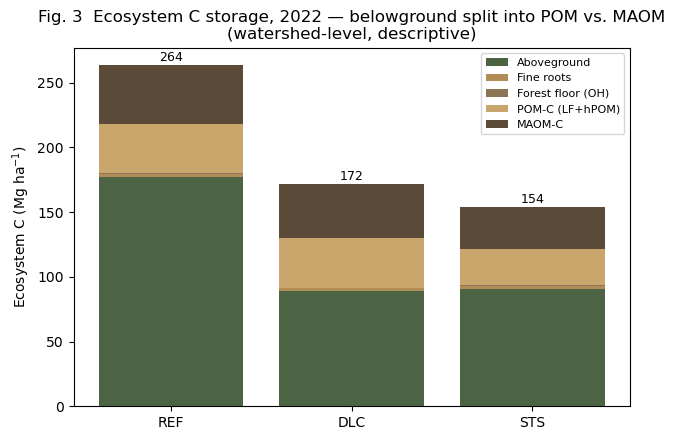

In [34]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
stack_cols = ['Aboveground', 'Fine roots', 'Forest floor (OH)', 'POM-C (LF+hPOM)', 'MAOM-C']
stack_colors = ['#4C6444', '#B08D57', '#8B7355', '#C9A66B', '#5C4A38']
bottom = np.zeros(3)
for col, c in zip(stack_cols, stack_colors):
    ax.bar(eco.index, eco[col], bottom=bottom, label=col, color=c)
    bottom += eco[col].values
for i, tot in enumerate(eco['Total']):
    ax.text(i, tot + 3, f'{tot:.0f}', ha='center', fontsize=9)
ax.set_ylabel('Ecosystem C (Mg ha$^{-1}$)')
ax.set_title('Fig. 3  Ecosystem C storage, 2022 — belowground split into POM vs. MAOM\n(watershed-level, descriptive)')
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

In [35]:
def fmt(m, s):
    return f'{m:.1f} ± {s:.1f}'

r_agb = battery([agb_plot[agb_plot.watershed == w]['MgC_ha'].values for w in ORDER])
r_soil = battery([wide[wide.watershed == w]['SoilC_0_40'].values for w in ORDER])
lf_p_range = '0.004–0.013'

table1 = pd.DataFrame([
    ['AGB-C (Mg/ha)', fmt(r_agb['means'][0], r_agb['sds'][0]), fmt(r_agb['means'][1], r_agb['sds'][1]),
     fmt(r_agb['means'][2], r_agb['sds'][2]),
     f"Welch p={r_agb['pw']:.3f}; KW p={r_agb['pk']:.3f}",
     f"Dunnett DLC p={r_agb['dunnett_p'][0]:.3f}, STS p={r_agb['dunnett_p'][1]:.3f}; Levene fails -> Welch/KW lead"],
    ['Mineral soil C 0-40 cm (Mg/ha)', fmt(r_soil['means'][0], r_soil['sds'][0]),
     fmt(r_soil['means'][1], r_soil['sds'][1]), fmt(r_soil['means'][2], r_soil['sds'][2]),
     f"ANOVA p={r_soil['p']:.3f}", f"not detected; power={r_soil['power']:.2f}"],
    ['Subsoil LF-C 20-40 cm (g/m2)', f'{ref.mean():.0f}', f'{dlc.mean():.0f}',
     f'{np.nanmean(sts):.0f} (3/6 censored)', f'ANOVA p={lf_p_range} (censoring sensitivity)',
     'DLC/REF = 2.2x; Welch t p=0.007; robust to all substitution choices'],
    ['Ecosystem C total (Mg/ha)', f"{eco.loc['REF', 'Total']:.0f}", f"{eco.loc['DLC', 'Total']:.0f}",
     f"{eco.loc['STS', 'Total']:.0f}", 'descriptive (n=1 watershed/treatment)',
     f"% belowground: {eco.loc['REF', '% belowground']:.0f} / {eco.loc['DLC', '% belowground']:.0f} / {eco.loc['STS', '% belowground']:.0f}"],
], columns=['Variable', 'REF', 'DLC', 'STS', 'Primary test', 'Notes'])
table1


,Variable,REF,DLC,STS,Primary test,Notes
0,AGB-C (Mg/ha),177.4 ± 44.8,89.0 ± 14.8,90.6 ± 42.4,Welch p=0.007; KW p=0.008,"Dunnett DLC p=0.007, STS p=0.007; Levene fails..."
1,Mineral soil C 0-40 cm (Mg/ha),83.7 ± 18.8,80.4 ± 24.2,60.7 ± 10.9,ANOVA p=0.105,not detected; power=0.44
2,Subsoil LF-C 20-40 cm (g/m2),452,1010,675 (3/6 censored),ANOVA p=0.004–0.013 (censoring sensitivity),DLC/REF = 2.2x; Welch t p=0.007; robust to all...
3,Ecosystem C total (Mg/ha),264,172,154,descriptive (n=1 watershed/treatment),% belowground: 33 / 48 / 41


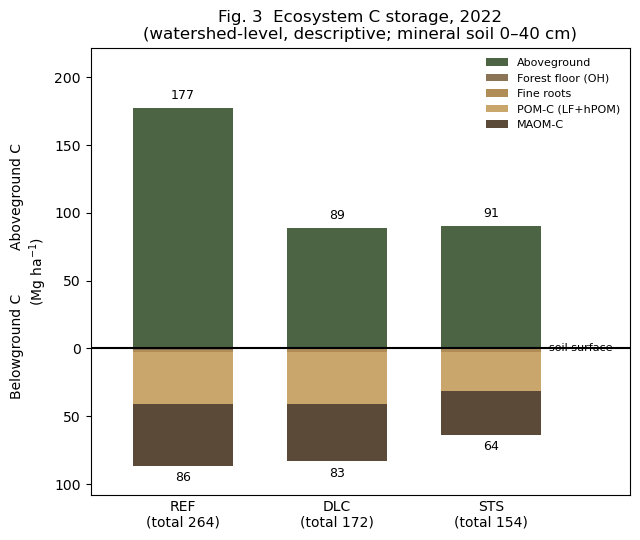

In [36]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(6.5, 5.5))
x = np.arange(len(eco.index)); w = 0.65

# Aboveground: up from the soil surface
ax.bar(x, eco['Aboveground'], width=w, color='#4C6444', label='Aboveground')

# Belowground: down from the soil surface, in profile order (surface -> deepest/most protected)
below_cols   = ['Forest floor (OH)', 'Fine roots', 'POM-C (LF+hPOM)', 'MAOM-C']
below_colors = ['#8B7355', '#B08D57', '#C9A66B', '#5C4A38']
bottom = np.zeros(len(x))
for col, c in zip(below_cols, below_colors):
    ax.bar(x, -eco[col], bottom=bottom, width=w, color=c, label=col)
    bottom -= eco[col].values

# Soil surface
ax.axhline(0, color='k', linewidth=1.5)
ax.text(x[-1] + w / 2 + 0.05, 0, 'soil surface', va='center', ha='left', fontsize=8)

# Totals: aboveground above each bar, belowground below, ecosystem total in the label
above = eco['Aboveground'].values
below = eco[below_cols].sum(axis=1).values
for xi, a, b in zip(x, above, below):
    ax.text(xi, a + 4, f'{a:.0f}', ha='center', va='bottom', fontsize=9)
    ax.text(xi, -b - 4, f'{b:.0f}', ha='center', va='top', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f'{i}\n(total {t:.0f})' for i, t in zip(eco.index, eco['Total'])])
ax.tick_params(axis='x', length=0)

# Absolute values on the y-axis, with room for labels and legend
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.0f}'))
ax.set_ylim(-below.max() * 1.25, above.max() * 1.25)
ax.set_xlim(-0.6, len(x) - 0.1)
ax.set_ylabel('Belowground C          Aboveground C\n(Mg ha$^{-1}$)')
ax.set_title('Fig. 3  Ecosystem C storage, 2022\n(watershed-level, descriptive; mineral soil 0–40 cm)')

# Legend reads top-to-bottom in the same order as the profile
ax.legend(fontsize=8, loc='upper right', frameon=False)

plt.tight_layout(); plt.show()